In order to run the bellow cells, download Amazon datasets for electronics from https://amazon-reviews-2023.github.io/main.html and place them in the /data folder.

### Import Dependencies

In [2]:
import json
import gzip
import pandas as pd

### Working with downloaded data 

In [3]:
with gzip.open("../../data/meta_Home_and_Kitchen.jsonl.gz", "rt") as f:
    first_line = json.loads(f.readline())

In [4]:
first_line

{'main_category': 'Amazon Home',
 'title': 'Set of 4 Irish Coffee Glass Mugs Footed 10.5 oz.Thick Wall Glass For Coffee, tea, Cappuccinos, Mulled Ciders,Hot Chocolates, Ice cream and More',
 'average_rating': 4.6,
 'rating_number': 18,
 'features': ['☕PERFECT IRISH COFFEE MUG: With our clear glass 10.5 ounce makes it a perfect mug for offering up your signature Coffee Drinks, Cappuccinos, Milk shakes, Dessert, Sundae and much more!',
  '☕FOOTED BOTTOM - Footed Bottom for an elegant look and easy sipping',
  '☕COFFEE & MORE-You can serve your favorite cappuccino, tea, coffee, ice cream,milk shakes,desserts and more!',
  '☕HIGHLY DURABLE GLASS - Our Irish Coffee Mugs are extremely durable with thick glass to ensure optimal durability for excellent service!',
  '☕DIMENSIONS: 12.8 x 11.8 x 5.3 inches'],
 'description': ['Set of 12 Footed 10.5 oz. Irish coffee mug the perfect vessel for offering up your signature cappuccinos, mulled ciders, hot chocolates, and more! With its ornate stem and

### Filter out only recent items (appeared in stock in 2022 or 2023)

In [6]:
def filter_data_by_date(data: dict) -> bool:
    filter = False
    if int(data["details"]["Date First Available"][-4:]) < 2022:
        filter = True
    return filter

In [7]:
filter_data_by_date(first_line)

True

In [9]:
with gzip.open("../../data/meta_Home_and_Kitchen.jsonl.gz", 'rt') as fp:
    with open("../../data/meta_Home_and_Kitchen_2022_2023.jsonl", 'a', encoding='utf-8') as fp_out:
        with open("../../data/meta_Home_and_Kitchen_2022_2023_no_date.jsonl", 'a', encoding='utf-8') as fp_out_no_date:
            i = 0
            for line in fp:
                data = json.loads(line.strip())
                try:
                    filter = filter_data_by_date(data)
                    if not filter:
                        json.dump(data, fp_out)
                        fp_out.write('\n')
                        fp_out.flush()
                except:
                    json.dump(data, fp_out_no_date)
                    fp_out_no_date.write('\n')
                    fp_out_no_date.flush()
                i += 1
                if i % 10000 == 0:
                    print(f"Processed {i} lines")

Processed 10000 lines
Processed 20000 lines
Processed 30000 lines
Processed 40000 lines
Processed 50000 lines
Processed 60000 lines
Processed 70000 lines
Processed 80000 lines
Processed 90000 lines
Processed 100000 lines
Processed 110000 lines
Processed 120000 lines
Processed 130000 lines
Processed 140000 lines
Processed 150000 lines
Processed 160000 lines
Processed 170000 lines
Processed 180000 lines
Processed 190000 lines
Processed 200000 lines
Processed 210000 lines
Processed 220000 lines
Processed 230000 lines
Processed 240000 lines
Processed 250000 lines
Processed 260000 lines
Processed 270000 lines
Processed 280000 lines
Processed 290000 lines
Processed 300000 lines
Processed 310000 lines
Processed 320000 lines
Processed 330000 lines
Processed 340000 lines
Processed 350000 lines
Processed 360000 lines
Processed 370000 lines
Processed 380000 lines
Processed 390000 lines
Processed 400000 lines
Processed 410000 lines
Processed 420000 lines
Processed 430000 lines
Processed 440000 lin

### Split the items into two categories: "has main category", "does not have main category"

In [10]:
def filter_category(data: dict) -> dict:
    filter = False
    if data['main_category'] == None:
        filter = True
        
    return filter

In [11]:
with open("../../data/meta_Home_and_Kitchen_2022_2023.jsonl", 'r') as fp:
    with open("../../data/meta_Home_and_Kitchen_2022_2023_with_category.jsonl", 'a', encoding='utf-8') as fp_out:
        with open("../../data/meta_Home_and_Kitchen_2022_2023_no_category.jsonl", 'a', encoding='utf-8') as fp_out_no_category:
            i = 0
            for line in fp:
                data = json.loads(line.strip())
                if not filter_category(data):
                    json.dump(data, fp_out)
                    fp_out.write('\n')
                    fp_out.flush()
                else:
                    json.dump(data, fp_out_no_category)
                    fp_out_no_category.write('\n')
                    fp_out_no_category.flush()
                i += 1
                if i % 10000 == 0:
                    print(f"Processed {i} lines")

Processed 10000 lines
Processed 20000 lines
Processed 30000 lines
Processed 40000 lines
Processed 50000 lines
Processed 60000 lines
Processed 70000 lines
Processed 80000 lines
Processed 90000 lines
Processed 100000 lines
Processed 110000 lines
Processed 120000 lines
Processed 130000 lines
Processed 140000 lines
Processed 150000 lines
Processed 160000 lines
Processed 170000 lines
Processed 180000 lines
Processed 190000 lines
Processed 200000 lines
Processed 210000 lines
Processed 220000 lines
Processed 230000 lines
Processed 240000 lines
Processed 250000 lines
Processed 260000 lines
Processed 270000 lines
Processed 280000 lines
Processed 290000 lines
Processed 300000 lines
Processed 310000 lines


### Explore distrubution categories

In [12]:
df = pd.read_json("../../data/meta_Home_and_Kitchen_2022_2023_with_category.jsonl", lines=True)

In [13]:
df.head()

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,Amazon Home,Foaming Soap Dispenser Thick Ceramic Foam Hand...,4.4,135,[Saving money: You can DIY foam soap which wil...,[],24.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Foaming Soap Dispenser Ceramic Foa...,rejomiik,"[Home & Kitchen, Bath]",{'Package Dimensions': '7.32 x 6.14 x 3.94 inc...,B0BNZ8Q7YT,NaN
1,Amazon Home,"KatchOn, Easter Window Clings Decorations - 18...",3.8,17,"[PACK OF 183 | 9 SHEETS, ADORABLE SPRING WINDO...",[],8.97,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Cute Easter Window Clings for Kids...,KatchOn,"[Home & Kitchen, Home Décor Products, Window T...","{'Brand': 'KatchOn', 'Color': 'Pack of 183', '...",B0BXD63CMC,NaN
2,Amazon Home,"Wood Coasters with Holder, GOH DODD Wooden Dri...",4.6,311,[HANDCRAFTED COASTERS: Made of natural cedar w...,[],28.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'I think you’ll like this one!', 'u...",GOH DODD,"[Home & Kitchen, Kitchen & Dining, Dining & En...","{'Color': 'Brown, Clear', 'Material': 'Wood, C...",B09PQRW951,NaN
3,Tools & Home Improvement,WSICSE 14Pcs Portable Stainless Steel Toothpic...,4.3,555,[【Material】Our toothpicks are made of stainles...,"[Specifications:, Color: SliverPackage Size: 5...",9.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Reusable metal toothpicks', 'url':...",WSICSE,"[Home & Kitchen, Kitchen & Dining, Kitchen Ute...","{'Manufacturer': 'WSICSE', 'Part Number': 'D26...",B0B7XLFVSP,NaN
4,Amazon Home,"CELBERENA Shower Curtain Liner 72x80 Inch, PEV...",4.4,16,[✚ Premium Quality: Shower curtain liner is ma...,[],11.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'CELBERENA Shower Curtain Liner 72x...,CELBERENA,"[Home & Kitchen, Bath, Bathroom Accessories, S...","{'Brand': 'CELBERENA', 'Color': 'Generous Show...",B0BXCZTWV2,NaN


In [14]:
len(df)

267641

Matplotlib is building the font cache; this may take a moment.


<Axes: xlabel='main_category'>

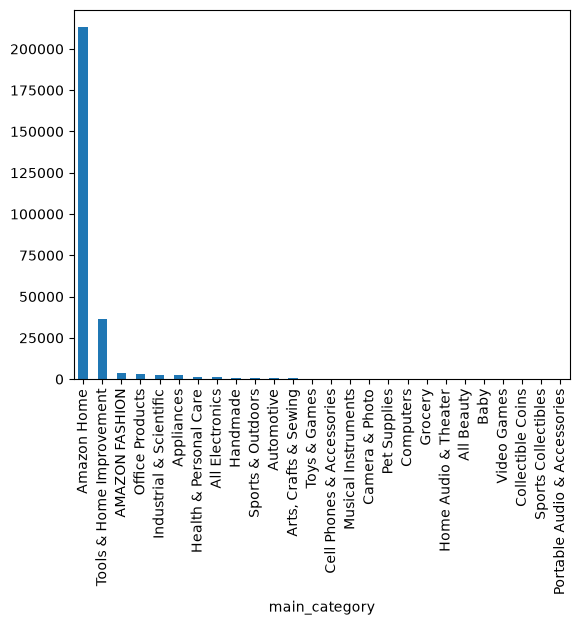

In [16]:
df['main_category'].value_counts().plot(kind='bar')

### Filter out items that have at least 100 ratings

In [17]:
df_rating_100 = df[df["rating_number"] >= 100]

In [18]:
len(df_rating_100)

35121

<Axes: xlabel='main_category'>

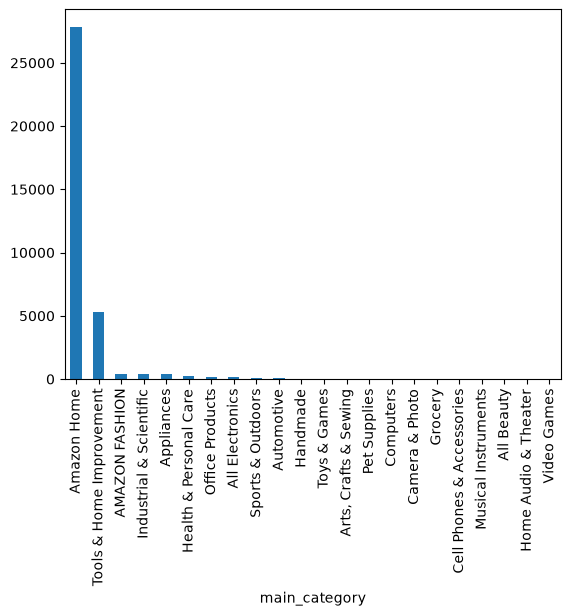

In [19]:
df_rating_100['main_category'].value_counts().plot(kind='bar')

### Explore distribution of ratings

<Axes: ylabel='Frequency'>

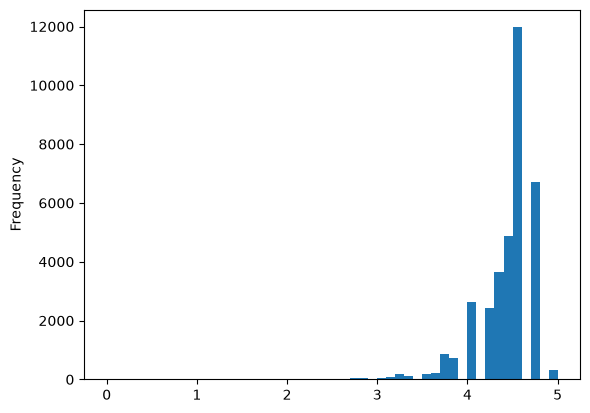

In [20]:
df_rating_100['average_rating'].plot(kind='hist', bins=50, range=(0,5))

### Sample 1000 items

In [21]:
df_sample_1000 = df_rating_100.sample(n=1000, random_state=42)

In [22]:
len(df_sample_1000)

1000

<Axes: ylabel='Frequency'>

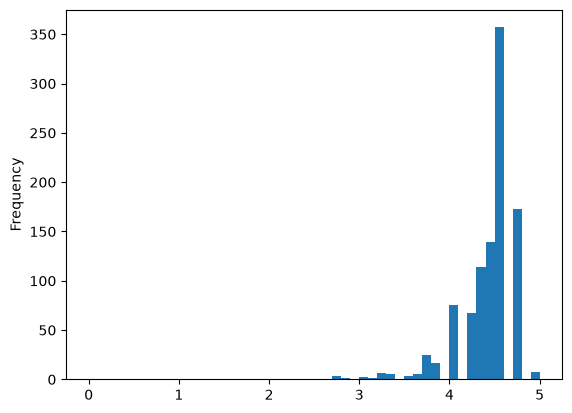

In [23]:
df_sample_1000['average_rating'].plot(kind='hist', bins=50, range=(0,5))

<Axes: ylabel='Frequency'>

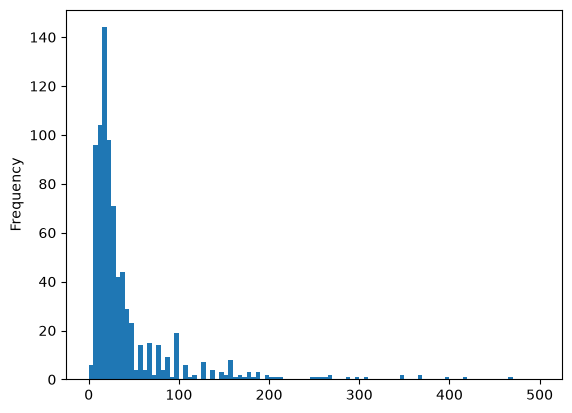

In [24]:
df_sample_1000['price'].plot(kind='hist', bins=100, range=(0,500))

<Axes: xlabel='main_category'>

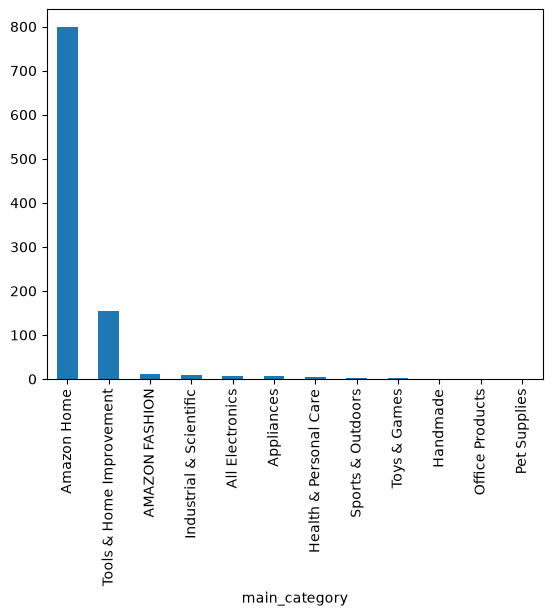

In [26]:
df_sample_1000['main_category'].value_counts().plot(kind='bar')

In [27]:
df_sample_1000.to_json("../../data/meta_Home_and_Kitchen_2022_2023_with_category_ratings_100_sample_1000.jsonl", orient="records", lines=True)

### Test file

In [28]:
df_test = pd.read_json("../../data/meta_Home_and_Kitchen_2022_2023_with_category_ratings_100_sample_1000.jsonl", lines=True)

In [29]:
df_test.head()

,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,Amazon Home,"MOTPK Gaming Desk L Shaped, Small Corner Desk ...",4.6,303,[Large Monitor Shelf & 2-layer Storage Shelf: ...,[],159.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Bestier Gaming Desk with LED Light...,MOTPK,"[Home & Kitchen, Furniture, Home Office Furnit...","{'Brand': 'MOTPK', 'Shape': 'L-Shape', 'Produc...",B0B69HZCMZ,NaN
1,Amazon Home,"Luminous Gesture Octopus with Mother of Pearl,...",3.4,138,[【Creative Ornaments】 This is an octopus with ...,"[【Size and Material】W: 4.73 inches, H: 2.36 in...",13.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Looks Nothing Like the Picture', '...",Gladyell,"[Home & Kitchen, Home Décor Products, Home Déc...","{'Color': 'Light Blue', 'Brand': 'Gladyell', '...",B09SZ6VHNS,NaN
2,Amazon Home,Zinus Kai Bamboo and Metal Platform Bed Frame ...,4.4,168,"[STYLE, DEPENDABILITY, VALUE – Crafted from at...",[The Kai Bamboo and Metal Platform Bed Frame i...,126.00,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'ZINUS Kai Bamboo and Metal Platfor...,Zinus,"[Home & Kitchen, Furniture, Bedroom Furniture,...","{'Size': 'Full', 'Material': 'Bamboo', 'Produc...",B0BW9P7HYL,NaN
3,Amazon Home,"6FT Artificial Christmas Garland with Lights,C...",4.2,164,[【Superior Material & Durable】: Christmas garl...,[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Very good quality well made', 'url...",Ealeh,"[Home & Kitchen, Seasonal Décor, Wreaths, Garl...",{'Package Dimensions': '9.84 x 9.84 x 6.02 inc...,B0BCQPS89W,NaN
4,Amazon Home,"Baseola 4Pcs Straw Tip Covers, Dust-Proof Stra...",4.4,139,[Come with 4 pieces lovely Cat Paw straw cover...,[],4.99,[{'thumb': 'https://m.media-amazon.com/images/...,[],Baseola,"[Home & Kitchen, Kitchen & Dining, Kitchen Ute...",{'Package Dimensions': '4.45 x 3.39 x 1.26 inc...,B0C4HFZX97,NaN


In [30]:
len(df_test)

1000